# IDX Exchange DS Internship - Week Six - Feature Engineering

In [24]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from sklearn.preprocessing import TargetEncoder

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


--------

In [25]:
# Read in the training and test sets created earlier

train_set = pd.read_csv("week_3_train_2.csv")
test_set = pd.read_csv("week_3_test_2.csv")

To improve the performance of our models, we can create new features from our existing data. This new features should either improve the quality of the data or should capture some new relationship which is predictive of ClosePrice. This notebook is a workspace for creating these new features.

## Bed/Bath Ratio

The existing dataset includes counts for bedrooms and bathrooms. However, the ratio of bedrooms to bathrooms could be a helpful feature to add to our model. Since bedrooms tend to be bigger than bathrooms, properties with more bedrooms than bathrooms (and thus a higher Bed/Bath ratio) might be more desirable, and thus might have a higher ClosePrice.

count    265326.000000
mean          1.309586
std           0.259423
min           0.200000
25%           1.200000
50%           1.333333
75%           1.500000
max           6.000000
Name: BedBathRatio, dtype: float64

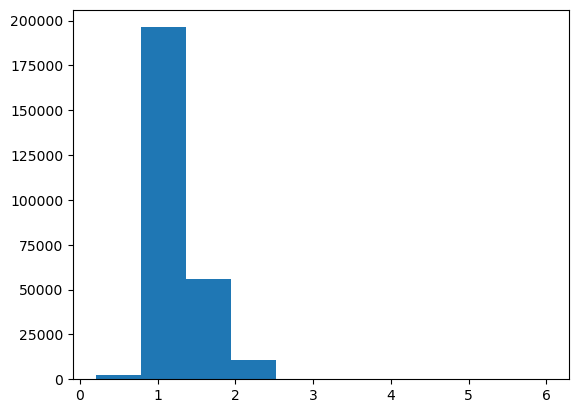

In [26]:
# Add one to both numerator and denominator to avoid dividing by zero

train_set["BedBathRatio"] =  (train_set["BedroomsTotal"] + 1) / (train_set["BathroomsTotalInteger"] + 1)
test_set["BedBathRatio"] =  (test_set["BedroomsTotal"] + 1) / (test_set["BathroomsTotalInteger"] + 1)

plt.hist(train_set["BedBathRatio"])
train_set["BedBathRatio"].describe()

## Age of Property

The age of a house can be a large factor in buying decisions. Our current model contains YearBuilt as a feature, however our model doesn't  know the current data, and therefore can't intuitively understand the age of a property just from YearBuilt. Let's create a new variable, AgeOfProperty, to encode this information.

count    265326.000000
mean         49.093070
std          27.368443
min          -1.000000
25%          27.000000
50%          49.000000
75%          69.000000
max         249.000000
Name: PropertyAge, dtype: float64

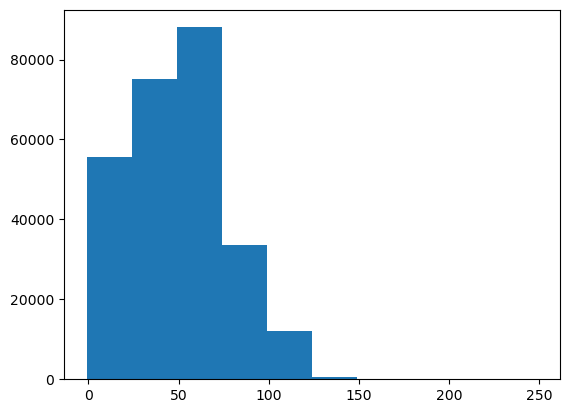

In [27]:
# Reminder: YearBuilt was imputed with the median YearBuilt of properties in each city

year_listed = pd.to_datetime(pd.to_datetime(train_set["PropertyMonth"]).dt.strftime("%Y"))
year_made = pd.to_datetime(train_set["YearBuilt"], format="%Y")
train_set["PropertyAge"] = year_listed.dt.year - year_made.dt.year

year_listed = pd.to_datetime(pd.to_datetime(test_set["PropertyMonth"]).dt.strftime("%Y"))
year_made = pd.to_datetime(test_set["YearBuilt"], format="%Y")
test_set["PropertyAge"] = year_listed.dt.year - year_made.dt.year

plt.hist(train_set["PropertyAge"])
train_set["PropertyAge"].describe()

## Precise School Districts

In our current dataset, the HighSchoolDistrict feature has a high amount of "Unknown" values. We can improve this feature by joining our dataset with the California School District Areas 2024-25 dataset (https://data.ca.gov/@california-department-of-education/california-school-district-areas-2024-25). This dataset has the name of California school districts, the type of district (high, elementary, unified), enrollment counts, demographic data, and the longitude/latitude that the district encompasses. We can take the longitude and latitude of each property in our MLS dataset and match this to the school districts in this new dataset to further enrich our features.

In [28]:
# Import the California School District Areas 2024-25 dataset.

gdf_geojson = gpd.read_file("California_School_District_Areas_2024-25.geojson")

In [29]:
gdf_geojson.columns

Index(['OBJECTID', 'Year', 'FedID', 'CDCode', 'CDSCode', 'CountyName',
       'DistrictName', 'DistrictType', 'GradeLow', 'GradeHigh',
       'GradeLowCensus', 'GradeHighCensus', 'AssistStatus', 'CongressUS',
       'SenateCA', 'AssemblyCA', 'UpdateNotes', 'EnrollTotal', 'EnrollCharter',
       'EnrollNonCharter', 'AAcount', 'AApct', 'AIcount', 'AIpct', 'AScount',
       'ASpct', 'FIcount', 'FIpct', 'HIcount', 'HIpct', 'PIcount', 'PIpct',
       'WHcount', 'WHpct', 'MRcount', 'MRpct', 'NRcount', 'NRpct', 'ELcount',
       'ELpct', 'FOScount', 'FOSpct', 'HOMcount', 'HOMpct', 'MIGcount',
       'MIGpct', 'SWDcount', 'SWDpct', 'SEDcount', 'SEDpct', 'DistrctAreaSqMi',
       'Shape__Area', 'Shape__Length', 'geometry'],
      dtype='object')

In [30]:
# A lot of these columns are just metadata. Keep only the relevant columns
# The kept columns relate to the name/type/county of the district, as well as enrollment counts and demographic information

cols_to_keep = ["CountyName", "DistrictName", "DistrictType",
                "EnrollTotal", "EnrollCharter", "EnrollNonCharter",
                "AApct", "AAcount", "AIpct", "AIcount", "ASpct", "AScount", "FIpct", "FIcount",
                "HIpct", "HIcount", "PIpct", "PIcount", "WHpct", "WHcount", "MRpct", "MRcount", 
                "NRpct", "NRcount", "ELpct", "ELcount", "FOSpct", "FOScount", "HOMpct", "HOMcount", 
                "MIGpct", "MIGcount", "SWDpct", "SWDcount", "SEDpct", "SEDcount", 
                "geometry"]

gdf_geojson = gdf_geojson[cols_to_keep]

In [31]:
# Merging the dataset naively creates duplicate rows where one property is matched to both its elementary
# and high school district, creating two rows for one property. To fix this, we must sequentially join the
# data together based on district type (high, elementary, unified).

### High School Distict Joining
geo_high = gdf_geojson[gdf_geojson["DistrictType"] == "High"]

# Train Set
geometry = gpd.points_from_xy(train_set["Longitude"], train_set["Latitude"])
gdf_points = gpd.GeoDataFrame(train_set, geometry=geometry, crs="EPSG:4326")
geo_high = geo_high.to_crs(gdf_points.crs)
geo_high_train = gpd.sjoin(gdf_points, geo_high, how="left", predicate="within")

# Test Set
geometry = gpd.points_from_xy(test_set["Longitude"], test_set["Latitude"])
gdf_points = gpd.GeoDataFrame(test_set, geometry=geometry, crs="EPSG:4326")
geo_high = geo_high.to_crs(gdf_points.crs)
geo_high_test = gpd.sjoin(gdf_points, geo_high, how="left", predicate="within")


### Elementary School District Joining
geo_elem = gdf_geojson[gdf_geojson["DistrictType"] == "Elementary"]

# Train Set
geometry = gpd.points_from_xy(train_set["Longitude"], train_set["Latitude"])
gdf_points = gpd.GeoDataFrame(train_set, geometry=geometry, crs="EPSG:4326")
geo_elem = geo_elem.to_crs(gdf_points.crs)
geo_elem_train = gpd.sjoin(gdf_points, geo_elem, how="left", predicate="within")

# Test Set
geometry = gpd.points_from_xy(test_set["Longitude"], test_set["Latitude"])
gdf_points = gpd.GeoDataFrame(test_set, geometry=geometry, crs="EPSG:4326")
geo_elem = geo_elem.to_crs(gdf_points.crs)
geo_elem_test = gpd.sjoin(gdf_points, geo_elem, how="left", predicate="within")


### Unified School District Joining
geo_unif = gdf_geojson[gdf_geojson["DistrictType"] == "Unified"]

# Train Set
geometry = gpd.points_from_xy(train_set["Longitude"], train_set["Latitude"])
gdf_points = gpd.GeoDataFrame(train_set, geometry=geometry, crs="EPSG:4326")
geo_unif = geo_unif.to_crs(gdf_points.crs)
geo_unif_train = gpd.sjoin(gdf_points, geo_unif, how="left", predicate="within")

# Test Set
geometry = gpd.points_from_xy(test_set["Longitude"], test_set["Latitude"])
gdf_points = gpd.GeoDataFrame(test_set, geometry=geometry, crs="EPSG:4326")
geo_unif = geo_unif.to_crs(gdf_points.crs)
geo_unif_test = gpd.sjoin(gdf_points, geo_unif, how="left", predicate="within")

In [34]:
# Join the datasets sequentially

geo_elem_train = geo_elem_train[cols_to_keep]
geo_unif_train = geo_unif_train[cols_to_keep]
geo_unif_train = geo_unif_train.add_suffix('_unif')
geo_train = geo_high_train.join(geo_elem_train, how="inner", lsuffix='_high', rsuffix='_elem').join(geo_unif_train, how="inner")

geo_elem_test = geo_elem_test[cols_to_keep]
geo_unif_test = geo_unif_test[cols_to_keep]
geo_unif_test = geo_unif_test.add_suffix('_unif')
geo_test = geo_high_test.join(geo_elem_test, how="inner", lsuffix='_high', rsuffix='_elem').join(geo_unif_test, how="inner")

In [35]:
geo_train[["HighSchoolDistrict", "DistrictName_elem", "DistrictName_high", "DistrictName_unif"]]

,HighSchoolDistrict,DistrictName_elem,DistrictName_high,DistrictName_unif
0,Unknown,National Elementary,Sweetwater Union High,NaN
1,Unknown,National Elementary,Sweetwater Union High,NaN
2,San Luis Coastal Unified,NaN,NaN,San Luis Coastal Unified
3,Unknown,NaN,NaN,Fort Bragg Unified
4,Other,Evergreen Elementary,East Side Union High,NaN
...,...,...,...,...
265321,Los Angeles Unified,NaN,NaN,Los Angeles Unified
265322,Los Angeles Unified,NaN,NaN,Los Angeles Unified
265323,Victor Valley Unified,Adelanto Elementary,Victor Valley Union High,NaN
265324,Rim of the World,NaN,NaN,Rim of the World Unified


In [36]:
# Check if there are any rows in the MLS data that could not be matched to any school district
# It seems that most of these rows show up as "Unknown" or "Other" 

condition_train = (geo_train["DistrictName_high"].isna() == True) & (geo_train["DistrictName_elem"].isna() == True) & (geo_train["DistrictName_unif"].isna() == True)
condition_test = (geo_test["DistrictName_high"].isna() == True) & (geo_test["DistrictName_elem"].isna() == True) & (geo_test["DistrictName_unif"].isna() == True)

geo_train[condition_train]["HighSchoolDistrict"].value_counts()

# Since there are only 36 of these rows, this is a low enough number to just drop
geo_train = geo_train.drop(geo_train[condition_train].index).reset_index(drop=True)
geo_test = geo_test.drop(geo_test[condition_test].index).reset_index(drop=True)

In [37]:
# Drop the DistrictType column since this information is encoded in the column title of DistrictName

geo_train = geo_train.drop(columns = ["DistrictType_elem", "DistrictType_high", "DistrictType_unif"])
geo_test = geo_test.drop(columns = ["DistrictType_elem", "DistrictType_high", "DistrictType_unif"])

In [38]:
# Fill Unknown HighSchoolDistrict with DistrictName

geo_train["HighSchoolDistrict"] = np.where(geo_train["HighSchoolDistrict"] == "Unknown",
                                           geo_train["DistrictName_high"], geo_train["HighSchoolDistrict"])
geo_train["HighSchoolDistrict"] = np.where(geo_train["HighSchoolDistrict"] == "Other",
                                            geo_train["DistrictName_high"], geo_train["HighSchoolDistrict"])

geo_test["HighSchoolDistrict"] = np.where(geo_test["HighSchoolDistrict"] == "Unknown",
                                            geo_test["DistrictName_high"], geo_test["HighSchoolDistrict"])
geo_test["HighSchoolDistrict"] = np.where(geo_test["HighSchoolDistrict"] == "Other",
                                            geo_test["DistrictName_high"], geo_test["HighSchoolDistrict"])

In [39]:
# Now HighSchoolDistrict serves as DistrictName_high, so drop DistrictName_high

geo_train = geo_train.drop(columns = ["DistrictName_high"])
geo_test = geo_test.drop(columns = ["DistrictName_high"])

In [40]:
# Clean up remaning rows

geo_train = geo_train.rename(columns={"HighSchoolDistrict": "DistrictName_high"})
geo_test = geo_test.rename(columns={"HighSchoolDistrict": "DistrictName_high"})

geo_train = geo_train.drop(columns = ["geometry_high", "index_right", "CountyName_high", "CountyName_elem", "geometry_elem",
                                      "CountyName_unif", "geometry_unif"])
geo_test = geo_test.drop(columns = ["geometry_high", "index_right", "CountyName_high", "CountyName_elem", "geometry_elem",
                                      "CountyName_unif", "geometry_unif"])

In [41]:
# Fill categorical null values with "N/A"
cat = ["DistrictName_elem", "DistrictName_unif", "DistrictName_high"]
 
geo_train[cat] = geo_train[cat].fillna("N/A")
geo_test[cat] = geo_test[cat].fillna("N/A")

# Fill numerical null values with 0
num =  ['EnrollTotal_high', 'EnrollCharter_high', 'EnrollNonCharter_high', 'AApct_high', 'AAcount_high', 'AIpct_high',
        'AIcount_high', 'ASpct_high', 'AScount_high', 'FIpct_high', 'FIcount_high', 'HIpct_high', 'HIcount_high', 'PIpct_high',
        'PIcount_high', 'WHpct_high', 'WHcount_high', 'MRpct_high', 'MRcount_high', 'NRpct_high', 'NRcount_high', 'ELpct_high',
        'ELcount_high', 'FOSpct_high', 'FOScount_high','HOMpct_high','HOMcount_high','MIGpct_high','MIGcount_high','SWDpct_high',
        'SWDcount_high','SEDpct_high','SEDcount_high', 'EnrollTotal_elem','EnrollCharter_elem','EnrollNonCharter_elem','AApct_elem',
        'AAcount_elem','AIpct_elem','AIcount_elem','ASpct_elem','AScount_elem','FIpct_elem','FIcount_elem','HIpct_elem','HIcount_elem',
        'PIpct_elem','PIcount_elem','WHpct_elem','WHcount_elem','MRpct_elem','MRcount_elem','NRpct_elem','NRcount_elem','ELpct_elem',
        'ELcount_elem','FOSpct_elem','FOScount_elem','HOMpct_elem','HOMcount_elem','MIGpct_elem','MIGcount_elem','SWDpct_elem',
        'SWDcount_elem','SEDpct_elem','SEDcount_elem','EnrollTotal_unif','EnrollCharter_unif','EnrollNonCharter_unif','AApct_unif',
        'AAcount_unif','AIpct_unif','AIcount_unif','ASpct_unif','AScount_unif','FIpct_unif','FIcount_unif','HIpct_unif','HIcount_unif',
        'PIpct_unif','PIcount_unif','WHpct_unif','WHcount_unif','MRpct_unif','MRcount_unif','NRpct_unif','NRcount_unif','ELpct_unif',
        'ELcount_unif','FOSpct_unif','FOScount_unif','HOMpct_unif','HOMcount_unif','MIGpct_unif','MIGcount_unif','SWDpct_unif',
        'SWDcount_unif','SEDpct_unif','SEDcount_unif']

geo_train[num] = geo_train[num].fillna(0)
geo_test[num] = geo_test[num].fillna(0)

## Target Encode the Categorical Variables

In [42]:
# Perform target encoding on: DistrictName_elem, DistrictName_unif, DistrictName_high

to_encode_train = geo_train[cat]
to_encode_test = geo_test[cat]

encoder = TargetEncoder(smooth="auto", cv=5, random_state=42)

train_encoded = encoder.fit_transform(to_encode_train, geo_train["ClosePriceLog"])
test_encoded = encoder.transform(to_encode_test)

train_encoded_df = pd.DataFrame(train_encoded, columns=to_encode_train.columns)
test_encoded_df = pd.DataFrame(test_encoded, columns=to_encode_train.columns)

geo_train = geo_train.join(train_encoded_df, rsuffix='_enc')
geo_test = geo_test.join(test_encoded_df, rsuffix='_enc')

## Summary

In [23]:
# Save the new dataset

geo_train.to_csv("feat_eng_train.csv", index=False)
geo_test.to_csv("feat_eng_test.csv", index=False)

After performing feature engineering on our dataset, its shape has changed from (bah, bah) to (bah, bah). While each of these features have been created with the intuition that these capture information whihc should help predict ClosePrice, we have yet to see whether they actually work in practice. The next step is to compare the performance of this new dataset to the old one using the Linear Regression and Decision Tree / Random Forest models we previously worked with. Refer back to 03_baseline_model.ipynb and 04_model_comparison.ipynb to view these comparisons.